# ClimaCity Paris -- 03. Spark SQL et Delta Lake (Jour 2 matin)

Ce carnet répond en **SQL** aux questions de l'équipe métier, puis persiste les résultats en **Delta Lake** :

1. vues temporaires `disponibilite`, `meteo_horaire`, `jours_feries`, et vue de travail `releves` ;
2. **Q1** : les dix stations le plus souvent vides entre 8 h et 10 h, jours ouvrés hors fériés ;
3. **fonctions de fenêtre** : `LAG`, `LEAD`, moyenne mobile sur 3 heures ;
4. **Q2** : la pluie réduit-elle les déplacements, et de combien ?
5. **Q3** : la station à la plus forte saisonnalité intra-journalière ;
6. **Delta Lake** : écriture, `MERGE INTO` pour corriger des données, puis time travel (`VERSION AS OF 0`).

Le carnet ne lit que les fichiers écrits par le carnet 02 (`disponibilite_parquet`, `meteo_horaire`).

> **Contexte de la période.** L'hiver 2020-2021 est celui du **couvre-feu** (20 h à partir du
> 15 décembre, 18 h à partir du 16 janvier) puis du **troisième confinement** (à partir du 3 avril). Les
> usages du soir y sont atypiques ; les conclusions valent pour cette période.

## 1. Session et vues temporaires

On enregistre les tables du carnet 02 comme **vues temporaires** : elles n'existent que dans la session
et ne copient rien, une requête SQL sur une vue relit le Parquet. `disponibilite` ne garde que les
colonnes du schéma cible, pour que les requêtes reconstruisent elles-mêmes calendrier et jointures.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..", "scripts").resolve()))
from config import *          # chemins, SEED, SHUFFLE_PARTITIONS, creer_session()

import json
import shutil
import time
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

spark = creer_session("ClimaCity-03-spark-sql-delta")
sc = spark.sparkContext

COLONNES_CIBLE = ["station_id", "nom_station", "arrondissement", "latitude", "longitude", "horodatage",
                  "velos_mecaniques", "velos_electriques", "bornettes_libres", "capacite_totale",
                  "taux_occupation"]
spark.read.parquet(str(PARQUET_CONSOLIDE)).select(*COLONNES_CIBLE).createOrReplaceTempView("disponibilite")
spark.read.parquet(str(METEO_PARQUET)).createOrReplaceTempView("meteo_horaire")

for vue in ["disponibilite", "meteo_horaire"]:
    print(f"{vue:<15} {spark.table(vue).count():>11,} lignes | ".replace(",", " ")
          + ", ".join(spark.table(vue).columns))

disponibilite    10 769 262 lignes | station_id, nom_station, arrondissement, latitude, longitude, horodatage, velos_mecaniques, velos_electriques, bornettes_libres, capacite_totale, taux_occupation
meteo_horaire         3 240 lignes | horodatage, temperature_c, humidite_pct, precipitation_mm, vitesse_vent_kmh, est_pluie


### Jours fériés

La question 1 exclut les jours fériés. On les calcule plutôt que de les recopier : huit dates fixes et
trois dates qui dépendent de **Pâques** (lundi de Pâques, Ascension, lundi de Pentecôte), obtenue par
l'algorithme de Meeus. La table, minuscule, est créée en Spark puis enregistrée comme vue.

In [2]:
def date_paques(annee: int) -> date:
    """Date du dimanche de Pâques (calendrier grégorien, algorithme de Meeus).

    Args:
        annee: Année, par ex. 2021.

    Returns:
        La date du dimanche de Pâques.

    Example:
        >>> date_paques(2021)
        datetime.date(2021, 4, 4)
    """
    a, b, c = annee % 19, annee // 100, annee % 100
    d, e = divmod(b, 4)
    f = (b + 8) // 25
    g = (b - f + 1) // 3
    h = (19 * a + b - d - g + 15) % 30
    i, k = divmod(c, 4)
    l = (32 + 2 * e + 2 * i - h - k) % 7
    m = (a + 11 * h + 22 * l) // 451
    mois, jour = divmod(h + l - 7 * m + 114, 31)
    return date(annee, mois, jour + 1)


def jours_feries(annees: list[int]) -> list[tuple[date, str]]:
    """Jours fériés nationaux en France métropolitaine.

    Args:
        annees: Années à couvrir.

    Returns:
        Une liste de couples ``(date, libellé)``, triée par date.

    Example:
        >>> jours_feries([2021])[0]
        (datetime.date(2021, 1, 1), "Jour de l'an")
    """
    fixes = [(1, 1, "Jour de l'an"), (5, 1, "Fête du travail"), (5, 8, "Victoire 1945"),
             (7, 14, "Fête nationale"), (8, 15, "Assomption"), (11, 1, "Toussaint"),
             (11, 11, "Armistice 1918"), (12, 25, "Noël")]
    feries = []
    for annee in annees:
        paques = date_paques(annee)
        feries += [(date(annee, m, j), libelle) for m, j, libelle in fixes]
        feries += [(paques + timedelta(days=1), "Lundi de Pâques"),
                   (paques + timedelta(days=39), "Ascension"),
                   (paques + timedelta(days=50), "Lundi de Pentecôte")]
    return sorted(feries)


spark.createDataFrame(jours_feries([2020, 2021]), "date DATE, libelle STRING") \
     .createOrReplaceTempView("jours_feries")
spark.sql("""
    SELECT date, libelle FROM jours_feries
    WHERE date BETWEEN (SELECT to_date(min(horodatage)) FROM meteo_horaire)
                   AND (SELECT to_date(max(horodatage)) FROM meteo_horaire)
""").show()

+----------+---------------+
|      date|        libelle|
+----------+---------------+
|2020-12-25|           Noël|
|2021-01-01|   Jour de l'an|
|2021-04-05|Lundi de Pâques|
+----------+---------------+



### Vue de travail `releves`

Une vue SQL ajoute à chaque relevé :

- le calendrier à l'**heure de Paris** (`date`, `heure`, `jour_semaine` de 1 = lundi à 7), le drapeau
  `est_ferie` et le **type de jour** (`ouvré` du lundi au vendredi hors fériés, `repos` sinon) ;
- la **météo** de l'heure UTC la plus proche, par une jointure que l'on force en **broadcast** avec un
  *hint* SQL (`/*+ BROADCAST(m, f) */`).

`CACHE TABLE` matérialise la vue en mémoire : les requêtes suivantes ne relisent plus le Parquet.

In [3]:
spark.sql("""
CREATE OR REPLACE TEMP VIEW releves AS
WITH d AS (
    SELECT *,
           from_utc_timestamp(horodatage, 'Europe/Paris')          AS local,
           date_trunc('HOUR', horodatage + INTERVAL 30 MINUTES)    AS horodatage_heure
    FROM disponibilite
)
SELECT /*+ BROADCAST(m, f) */
       d.station_id, d.nom_station, d.arrondissement, d.latitude, d.longitude,
       d.horodatage, d.horodatage_heure, d.capacite_totale, d.bornettes_libres, d.taux_occupation,
       d.velos_mecaniques + d.velos_electriques                     AS velos,
       to_date(d.local)                                             AS date,
       hour(d.local)                                                AS heure,
       weekday(d.local) + 1                                         AS jour_semaine,
       f.date IS NOT NULL                                           AS est_ferie,
       CASE WHEN weekday(d.local) < 5 AND f.date IS NULL THEN 'ouvré' ELSE 'repos' END AS type_jour,
       m.temperature_c, m.precipitation_mm, m.est_pluie
FROM d
LEFT JOIN meteo_horaire m ON m.horodatage = d.horodatage_heure
LEFT JOIN jours_feries  f ON f.date = to_date(d.local)
""")

sc.setJobDescription("SQL : CACHE TABLE releves")
t0 = time.perf_counter()
spark.sql("CACHE TABLE releves")
t_cache = time.perf_counter() - t0
print(f"CACHE TABLE releves : {t_cache:.1f} s")
spark.sql("""
    SELECT type_jour, est_ferie, count(*) AS releves, count(DISTINCT date) AS jours,
           round(avg(CAST(est_pluie AS INT)), 4) AS part_pluie, sum(CAST(est_pluie IS NULL AS INT)) AS sans_meteo
    FROM releves GROUP BY type_jour, est_ferie ORDER BY type_jour, est_ferie
""").show()

CACHE TABLE releves : 5.5 s


+---------+---------+-------+-----+----------+----------+
|type_jour|est_ferie|releves|jours|part_pluie|sans_meteo|
+---------+---------+-------+-----+----------+----------+
|    ouvré|    false|7538046|   93|    0.0512|         0|
|    repos|    false|2987223|   36|    0.0422|         0|
|    repos|     true| 243993|    3|       0.0|         0|
+---------+---------+-------+-----+----------+----------+



## 2. Q1 -- Les dix stations le plus souvent en rupture entre 8 h et 10 h

Une station est **en rupture** quand elle n'a aucun vélo (`velos = 0`). La fréquence de collecte varie
(carnet 01) : on classe donc par la **part des relevés en rupture**, et non par leur nombre. On ne garde
que les stations suivies sur l'essentiel de la période (au moins 400 relevés dans le créneau), et on
ajoute le nombre de **jours distincts** avec au moins une rupture, plus parlant pour l'exploitation.

Créneau : de 8 h 00 à 9 h 59, heure de Paris (`heure IN (8, 9)`), jours ouvrés hors fériés.

In [4]:
sc.setJobDescription("SQL : Q1 ruptures 8 h - 10 h")
t0 = time.perf_counter()
q1 = spark.sql("""
WITH creneau AS (
    SELECT * FROM releves WHERE type_jour = 'ouvré' AND heure IN (8, 9)
),
par_station AS (
    SELECT station_id,
           first(nom_station)                                   AS nom_station,
           first(arrondissement)                                AS arrondissement,
           count(*)                                             AS releves,
           sum(CAST(velos = 0 AS INT))                          AS releves_en_rupture,
           count(DISTINCT date)                                 AS jours_observes,
           count(DISTINCT CASE WHEN velos = 0 THEN date END)    AS jours_avec_rupture,
           avg(capacite_totale)                                 AS capacite_moyenne
    FROM creneau
    GROUP BY station_id
    HAVING count(*) >= 400
)
SELECT RANK() OVER (ORDER BY releves_en_rupture / releves DESC)  AS rang,
       station_id, nom_station, arrondissement, releves, releves_en_rupture,
       round(100 * releves_en_rupture / releves, 1)               AS part_rupture_pct,
       jours_avec_rupture, jours_observes, round(capacite_moyenne) AS capacite
FROM par_station
ORDER BY rang
LIMIT 10
""")
q1_pd = q1.toPandas()
t_q1 = time.perf_counter() - t0
display(q1_pd)
print(f"Q1 en {t_q1:.1f} s")

,rang,station_id,nom_station,arrondissement,releves,releves_en_rupture,part_rupture_pct,jours_avec_rupture,jours_observes,capacite
0,1,20113,Piat - Parc de Belleville,20,493,187,37.9,66,91,21.0
1,2,20111,Villiers de l'Isle Adam - Pyrénées,20,493,170,34.5,56,91,20.0
2,3,20002,Square de la rue Pixérécourt,20,493,159,32.3,53,91,15.0
3,4,41210,Hôtel de ville de Fontenay-sous-Bois,41,493,157,31.8,43,91,20.0
4,5,41205,Maréchal Joffre - Verdun,41,493,144,29.2,36,91,20.0
5,6,18005,Tardieu - Chappe,18,493,142,28.8,56,91,18.0
6,6,20137,Borrégo - Gambetta,20,493,142,28.8,47,91,25.0
7,6,41209,Cimetière,41,493,142,28.8,41,91,15.0
8,9,20035,Pyrénées - Ménilmontant,20,493,141,28.6,50,91,26.0
9,9,20203,Evariste Galois,20,493,141,28.6,40,91,30.0


Q1 en 1.5 s


Pour situer ces chiffres : la même part de rupture, calculée sur l'ensemble des stations et par
arrondissement (communes hors Paris regroupées).

In [5]:
spark.sql("""
SELECT CASE WHEN arrondissement <= 20 THEN concat('Paris ', arrondissement) ELSE 'hors Paris' END AS zone,
       count(DISTINCT station_id)                       AS stations,
       round(100 * avg(CAST(velos = 0 AS INT)), 1)      AS part_rupture_pct
FROM releves
WHERE type_jour = 'ouvré' AND heure IN (8, 9)
GROUP BY 1
ORDER BY part_rupture_pct DESC
""").show(25)

+----------+--------+----------------+
|      zone|stations|part_rupture_pct|
+----------+--------+----------------+
|  Paris 20|      68|            10.4|
|  Paris 18|      60|             5.9|
|  Paris 14|      58|             4.8|
|  Paris 19|      62|             4.1|
|hors Paris|     387|             3.3|
|   Paris 9|      46|             3.3|
|  Paris 15|      90|             2.8|
|  Paris 16|      63|             2.4|
|  Paris 17|      60|             1.7|
|  Paris 10|      52|             1.6|
|  Paris 13|      66|             1.5|
|   Paris 5|      37|             1.4|
|  Paris 12|      67|             1.2|
|   Paris 8|      53|             1.1|
|  Paris 11|      57|             0.7|
|   Paris 6|      33|             0.5|
|   Paris 3|      14|             0.4|
|   Paris 4|      27|             0.2|
|   Paris 2|      25|             0.2|
|   Paris 1|      26|             0.2|
|   Paris 7|      30|             0.1|
+----------+--------+----------------+



Les dix stations le plus souvent vides le matin sont **toutes en hauteur** : six sur les hauts de Belleville et de Ménilmontant (20e), trois à Fontenay-sous-Bois (code 41, sur le plateau) et Tardieu - Chappe sur la butte Montmartre (18e). C'est le phénomène classique des stations en pente : on descend à vélo le matin, on remonte rarement, et la régulation (camions qui remontent les vélos) ne compense pas.

**Piat - Parc de Belleville** est vide sur 37,9 % des relevés entre 8 h et 10 h, et l'a été au moins une fois 66 jours ouvrés sur 91. À l'échelle des arrondissements, le 20e atteint 10,4 % de rupture le matin, contre moins de 0,5 % au centre (1er, 2e, 4e et 7e). Les ex aequo (rangs 6 et 9) viennent de ce que toutes ces stations ont exactement 493 relevés dans le créneau : elles ont été relevées à chaque passage du collecteur.

## 3. Fonctions de fenêtre : `LAG`, `LEAD` et moyenne mobile sur 3 heures

Pour chaque station, triée par horodatage :

- `LAG` / `LEAD` donnent le taux d'occupation du relevé **précédent** et **suivant**, avec l'**écart de
  temps réel** (en minutes) qui les sépare : la collecte a des trous (jusqu'à 92 h), un « relevé
  précédent » peut dater de la veille ;
- `delta_velos` = variation du nombre de vélos depuis le relevé précédent, base de l'indicateur de
  déplacements de la question 2 ;
- la **moyenne mobile sur 3 heures** utilise une fenêtre **en temps** (`RANGE BETWEEN INTERVAL 3 HOURS
  PRECEDING AND CURRENT ROW`) et non en nombre de lignes : avec une collecte irrégulière, « les 12
  relevés précédents » ne couvrent pas toujours 3 heures. On compte aussi les relevés qu'elle contient.

La table est mise en cache : la question 2 et l'écriture Delta la réutilisent.

In [6]:
spark.sql("""
CREATE OR REPLACE TEMP VIEW features_temporelles AS
SELECT station_id, horodatage, horodatage_heure, date, heure, jour_semaine, type_jour,
       est_pluie, temperature_c, velos, capacite_totale, taux_occupation,
       LAG(taux_occupation)  OVER w                                           AS taux_precedent,
       LEAD(taux_occupation) OVER w                                           AS taux_suivant,
       (unix_timestamp(horodatage) - unix_timestamp(LAG(horodatage) OVER w)) / 60   AS ecart_precedent_min,
       (unix_timestamp(LEAD(horodatage) OVER w) - unix_timestamp(horodatage)) / 60  AS ecart_suivant_min,
       velos - LAG(velos) OVER w                                              AS delta_velos,
       AVG(taux_occupation) OVER w3h                                          AS moyenne_mobile_3h,
       COUNT(*) OVER w3h                                                      AS releves_fenetre_3h
FROM releves
WINDOW w   AS (PARTITION BY station_id ORDER BY horodatage),
       w3h AS (PARTITION BY station_id ORDER BY horodatage
               RANGE BETWEEN INTERVAL 3 HOURS PRECEDING AND CURRENT ROW)
""")
sc.setJobDescription("SQL : CACHE TABLE features_temporelles")
t0 = time.perf_counter()
spark.sql("CACHE TABLE features_temporelles")
t_features = time.perf_counter() - t0
print(f"Fenêtres calculées et mises en cache en {t_features:.1f} s")

spark.sql("""
SELECT horodatage, round(taux_occupation, 3) AS taux, round(taux_precedent, 3) AS precedent,
       round(taux_suivant, 3) AS suivant, ecart_precedent_min AS ecart_min, delta_velos,
       round(moyenne_mobile_3h, 3) AS mm_3h, releves_fenetre_3h AS n_3h
FROM features_temporelles
WHERE station_id = 20113 AND date = DATE'2021-01-12' AND heure BETWEEN 7 AND 9
ORDER BY horodatage
""").show(truncate=False)

Fenêtres calculées et mises en cache en 6.5 s


+-------------------+-----+---------+-------+---------+-----------+-----+----+
|horodatage         |taux |precedent|suivant|ecart_min|delta_velos|mm_3h|n_3h|
+-------------------+-----+---------+-------+---------+-----------+-----+----+
|2021-01-12 06:43:00|0.048|0.238    |0.048  |45.0     |-4         |0.202|4   |
|2021-01-12 07:19:00|0.048|0.048    |0.0    |36.0     |0          |0.143|4   |
|2021-01-12 08:08:00|0.0  |0.048    |0.0    |49.0     |-1         |0.083|4   |
|2021-01-12 08:59:00|0.0  |0.0      |0.0    |51.0     |0          |0.024|4   |
+-------------------+-----+---------+-------+---------+-----------+-----+----+



Pourquoi une fenêtre en temps : par mois, on compare le nombre moyen de relevés dans la fenêtre de
3 heures et la durée réellement couverte par une fenêtre fixe de 12 lignes (`ROWS BETWEEN 11 PRECEDING`).

In [7]:
spark.sql("""
WITH lignes AS (
    SELECT date, releves_fenetre_3h, ecart_precedent_min,
           (unix_timestamp(horodatage) - unix_timestamp(LAG(horodatage, 11) OVER w)) / 3600 AS duree_12_lignes_h
    FROM features_temporelles
    WINDOW w AS (PARTITION BY station_id ORDER BY horodatage)
)
SELECT date_format(date, 'yyyy-MM')                   AS mois,
       round(avg(releves_fenetre_3h), 1)               AS releves_dans_3h,
       round(avg(duree_12_lignes_h), 1)                AS heures_couvertes_par_12_lignes,
       round(100 * avg(CAST(ecart_precedent_min > 60 AS INT)), 2) AS ecarts_sup_1h_pct
FROM lignes
GROUP BY 1 ORDER BY 1
""").show()

+-------+---------------+------------------------------+-----------------+
|   mois|releves_dans_3h|heures_couvertes_par_12_lignes|ecarts_sup_1h_pct|
+-------+---------------+------------------------------+-----------------+
|2020-11|           11.5|                           3.0|              0.0|
|2020-12|            9.2|                           4.1|             1.29|
|2021-01|            5.4|                           7.6|            12.36|
|2021-02|            8.9|                           4.6|             0.38|
|2021-03|            9.2|                           4.0|             0.44|
|2021-04|           11.3|                           3.1|              0.0|
+-------+---------------+------------------------------+-----------------+



L'exemple (Piat - Parc de Belleville, 12 janvier au matin) montre la collecte de janvier : des relevés espacés de 36 à 51 minutes, et une moyenne mobile qui ne contient que 4 relevés.

Le tableau mensuel justifie la fenêtre en temps : **en janvier, une fenêtre de 12 lignes couvre en moyenne 7,6 heures au lieu de 3**, et 12 % des écarts dépassent une heure. Une moyenne « sur les 12 derniers relevés » n'aurait donc pas le même sens selon le mois. La fenêtre `RANGE` garde une durée constante (3 heures), au prix d'un nombre de relevés variable (5,4 en janvier, 11,5 en novembre), conservé dans `releves_fenetre_3h`. La même précaution vaudra pour les variables retardées du carnet 05 : `ecart_precedent_min` permet d'écarter un « t-1 » vieux de plusieurs heures.

## 4. Q2 -- La pluie réduit-elle les déplacements ?

L'énoncé propose le **taux d'occupation** comme indicateur de substitution. On le complète par un
indicateur plus direct, tiré des fenêtres ci-dessus : les **mouvements de vélos**, somme des
`|delta_velos|` entre deux relevés distants d'au plus 45 minutes, ramenée à une station-heure. Chaque
retrait ou dépôt fait bouger ce compteur.

L'unité d'analyse est l'**heure du réseau** (3 240 heures au plus, on en garde celles qui ont des
relevés) : comparer 11 millions de relevés ferait croire à une précision illusoire, puisque tous les
relevés d'une même heure partagent la même météo.

In [8]:
spark.sql("""
CREATE OR REPLACE TEMP VIEW reseau_horaire AS
SELECT horodatage_heure,
       first(heure)                                                    AS heure,
       first(type_jour)                                                AS type_jour,
       first(est_pluie)                                                AS est_pluie,
       first(date)                                                     AS date,
       avg(taux_occupation)                                            AS taux_moyen,
       60 * sum(CASE WHEN ecart_precedent_min <= 45 THEN abs(delta_velos) END)
          / sum(CASE WHEN ecart_precedent_min <= 45 THEN ecart_precedent_min END) AS mouvements,
       count(*)                                                        AS releves
FROM features_temporelles
GROUP BY horodatage_heure
""")
sc.setJobDescription("SQL : Q2 comparaison brute")
spark.sql("""
SELECT est_pluie, count(*) AS heures,
       round(100 * avg(taux_moyen), 2) AS taux_moyen_pct,
       round(avg(mouvements), 3)       AS mouvements_par_station_heure
FROM reseau_horaire GROUP BY est_pluie ORDER BY est_pluie
""").show()

+---------+------+--------------+----------------------------+
|est_pluie|heures|taux_moyen_pct|mouvements_par_station_heure|
+---------+------+--------------+----------------------------+
|    false|  2918|         36.95|                        2.19|
|     true|   164|         38.27|                       1.496|
+---------+------+--------------+----------------------------+



La comparaison brute est **biaisée** : il pleut plus souvent à certaines heures, et l'usage dépend avant
tout de l'heure et du type de jour. On compare donc chaque heure de pluie aux **heures sèches de même
heure et de même type de jour** (stratification) :

- `ecart_taux` = taux de l'heure de pluie - taux moyen des heures sèches de sa strate ;
- `ecart_mouvements` = mouvements de l'heure de pluie / mouvements moyens des heures sèches - 1.

La moyenne de ces écarts est l'effet de la pluie ; on l'accompagne de son erreur type et d'une
statistique *t*. Les heures de pluie se suivent par épisodes : on calcule aussi un *t* prudent en
ne comptant qu'une observation par **jour** de pluie.

In [9]:
sc.setJobDescription("SQL : Q2 comparaison stratifiée")
q2 = spark.sql("""
WITH reference AS (
    SELECT *,
           avg(CASE WHEN NOT est_pluie THEN taux_moyen END) OVER strate  AS taux_sec,
           avg(CASE WHEN NOT est_pluie THEN mouvements END) OVER strate  AS mouvements_sec
    FROM reseau_horaire
    WHERE est_pluie IS NOT NULL
    WINDOW strate AS (PARTITION BY heure, type_jour)
),
ecarts AS (
    SELECT date,
           100 * (taux_moyen - taux_sec)          AS ecart_taux_points,
           100 * (mouvements / mouvements_sec - 1) AS ecart_mouvements_pct
    FROM reference
    WHERE est_pluie
)
SELECT count(*)                                AS heures_de_pluie,
       count(DISTINCT date)                    AS jours_de_pluie,
       avg(ecart_taux_points)                  AS ecart_taux_points,
       stddev(ecart_taux_points) / sqrt(count(*)) AS erreur_type_taux,
       avg(ecart_mouvements_pct)               AS ecart_mouvements_pct,
       stddev(ecart_mouvements_pct) / sqrt(count(*)) AS erreur_type_mouvements
FROM ecarts
""").first().asDict()

# t prudent : même écart et même dispersion, mais n = nombre de jours de pluie au lieu du nombre d'heures
reduction = (q2["jours_de_pluie"] / q2["heures_de_pluie"]) ** 0.5
for nom, ecart, erreur in [("taux d'occupation (points)", q2["ecart_taux_points"], q2["erreur_type_taux"]),
                           ("mouvements de vélos (%)", q2["ecart_mouvements_pct"], q2["erreur_type_mouvements"])]:
    t = ecart / erreur
    print(f"{nom:<28} écart {ecart:+6.2f} ± {1.96 * erreur:4.2f} (IC 95 %) | t = {t:6.1f} "
          f"| t prudent (1 obs. / jour) = {t * reduction:5.1f}")
print(f"{q2['heures_de_pluie']} heures de pluie réparties sur {q2['jours_de_pluie']} jours")

taux d'occupation (points)   écart  +1.33 ± 0.24 (IC 95 %) | t =   10.8 | t prudent (1 obs. / jour) =   6.0
mouvements de vélos (%)      écart -23.07 ± 4.39 (IC 95 %) | t =  -10.3 | t prudent (1 obs. / jour) =  -5.7
164 heures de pluie réparties sur 50 jours


Effet par moment de la journée, pour voir où la pluie pèse le plus :

In [10]:
q2_detail = spark.sql("""
WITH reference AS (
    SELECT *,
           avg(CASE WHEN NOT est_pluie THEN mouvements END) OVER strate AS mouvements_sec,
           avg(CASE WHEN NOT est_pluie THEN taux_moyen END) OVER strate AS taux_sec
    FROM reseau_horaire WHERE est_pluie IS NOT NULL
    WINDOW strate AS (PARTITION BY heure, type_jour)
)
SELECT CASE WHEN heure BETWEEN 7 AND 9 THEN '1. pointe du matin (7 h-10 h)'
            WHEN heure BETWEEN 10 AND 15 THEN '2. journée (10 h-16 h)'
            WHEN heure BETWEEN 16 AND 19 THEN '3. pointe du soir (16 h-20 h)'
            ELSE '4. soir et nuit' END                        AS moment,
       count(*)                                               AS heures_de_pluie,
       round(100 * avg(taux_moyen - taux_sec), 2)             AS ecart_taux_points,
       round(100 * avg(mouvements / mouvements_sec - 1), 1)   AS ecart_mouvements_pct
FROM reference WHERE est_pluie
GROUP BY 1 ORDER BY 1
""")
q2_detail.show(truncate=False)

+-----------------------------+---------------+-----------------+--------------------+
|moment                       |heures_de_pluie|ecart_taux_points|ecart_mouvements_pct|
+-----------------------------+---------------+-----------------+--------------------+
|1. pointe du matin (7 h-10 h)|19             |1.44             |-28.8               |
|2. journée (10 h-16 h)       |50             |1.75             |-29.1               |
|3. pointe du soir (16 h-20 h)|23             |3.14             |-34.3               |
|4. soir et nuit              |72             |0.43             |-14.2               |
+-----------------------------+---------------+-----------------+--------------------+



**Oui, la pluie réduit nettement les déplacements.** À heure et type de jour égaux, les vélos bougent **environ 23 % de moins** (intervalle à 95 % : de -27 % à -19 %). Le taux d'occupation, lui, **augmente de 1,3 point** (± 0,24) : moins de vélos circulent, donc plus de vélos restent à quai. L'indicateur de substitution de l'énoncé fonctionne, mais dans ce sens : c'est une **hausse** du taux d'occupation, et non une baisse, qui signale moins de déplacements.

Les deux effets restent largement significatifs avec le calcul prudent, qui ne compte qu'une observation par jour de pluie (t ≈ 6). La comparaison brute donnait le même signe (-32 % de mouvements, +1,3 point), mais elle mélangeait l'effet de la pluie et celui des heures où il pleut.

Par moment de la journée, l'effet est le plus fort en **pointe du soir** (-34 % de mouvements, +3,1 points) et en journée (-29 %), et plus faible le soir et la nuit (-14 %), où l'on circule peu de toute façon (couvre-feu). Réserves : il n'y a que 164 heures de pluie (5 % des heures), sur un seul hiver ; et le seuil de 0,5 mm/h range les petites pluies parmi les heures « sèches », ce qui tend plutôt à **sous-estimer** l'effet.

## 5. Q3 -- La station à la plus forte saisonnalité intra-journalière

Pour chaque station, on calcule son **profil journalier** : le taux d'occupation moyen par heure de la
journée, sur les jours ouvrés (le profil des jours de repos est différent et mélangerait deux régimes).
Deux mesures de saisonnalité :

- l'**amplitude** du profil (maximum - minimum des 24 moyennes horaires), facile à lire ;
- la **part de variance expliquée par l'heure** (R² : variance du profil / variance totale des relevés),
  qui dit si cette amplitude est régulière d'un jour à l'autre ou noyée dans le bruit.

On exige les 24 heures et au moins 60 relevés par heure.

In [11]:
sc.setJobDescription("SQL : Q3 saisonnalité intra-journalière")
t0 = time.perf_counter()
spark.sql("""
CREATE OR REPLACE TEMP VIEW profils AS
SELECT station_id, heure, avg(taux_occupation) AS taux_heure, count(*) AS releves
FROM releves WHERE type_jour = 'ouvré'
GROUP BY station_id, heure
""")
q3 = spark.sql("""
WITH totaux AS (
    SELECT station_id, first(nom_station) AS nom_station, first(arrondissement) AS arrondissement,
           avg(taux_occupation) AS taux_moyen, var_pop(taux_occupation) AS variance_totale
    FROM releves WHERE type_jour = 'ouvré' GROUP BY station_id
),
saisonnalite AS (
    SELECT p.station_id,
           max(taux_heure) - min(taux_heure)                       AS amplitude,
           max_by(heure, taux_heure)                               AS heure_max,
           min_by(heure, taux_heure)                               AS heure_min,
           sum(releves * pow(taux_heure - t.taux_moyen, 2)) / sum(releves) AS variance_profil,
           min(releves)                                            AS releves_min
    FROM profils p JOIN totaux t USING (station_id)
    GROUP BY p.station_id
    HAVING count(*) = 24 AND min(releves) >= 60
)
SELECT RANK() OVER (ORDER BY amplitude DESC)              AS rang,
       s.station_id, t.nom_station, t.arrondissement,
       round(s.amplitude, 3)                              AS amplitude,
       round(s.variance_profil / t.variance_totale, 3)    AS r2_heure,
       s.heure_max, s.heure_min, round(t.taux_moyen, 3)   AS taux_moyen
FROM saisonnalite s JOIN totaux t USING (station_id)
ORDER BY rang
""")
q3_pd = q3.limit(10).toPandas()
t_q3 = time.perf_counter() - t0
display(q3_pd)
print(f"Q3 en {t_q3:.1f} s")
print("Meilleures stations selon le R² :")
display(q3.orderBy(F.desc("r2_heure")).limit(5).toPandas())

,rang,station_id,nom_station,arrondissement,amplitude,r2_heure,heure_max,heure_min,taux_moyen
0,1,100018,Gare du Nord - Denain,10,0.826,0.817,22,12,0.460
1,2,5124,Erasme - Ulm,5,0.808,0.753,10,19,0.332
2,3,13049,Vincent Auriol - Louise Weiss,13,0.763,0.788,10,22,0.422
3,4,10203,Gare du Nord - Faubourg Saint-Denis,10,0.753,0.857,22,12,0.451
4,5,9023,Laffitte - Italiens,9,0.722,0.799,11,23,0.380
5,6,13051,Halle Freyssinet - Parvis Alan Turing,13,0.696,0.749,11,2,0.336
6,7,2013,Favart - Italiens,2,0.687,0.704,9,23,0.446
7,8,14112,Méchain - Faubourg Saint-Jacques,14,0.678,0.425,9,21,0.353
8,9,9034,Godot de Mauroy - Madeleine,9,0.673,0.726,15,23,0.487
9,10,18014,Léon - Doudeauville,18,0.673,0.673,22,11,0.459


Q3 en 3.1 s
Meilleures stations selon le R² :


,rang,station_id,nom_station,arrondissement,amplitude,r2_heure,heure_max,heure_min,taux_moyen
0,4,10203,Gare du Nord - Faubourg Saint-Denis,10,0.753,0.857,22,12,0.451
1,1,100018,Gare du Nord - Denain,10,0.826,0.817,22,12,0.460
2,5,9023,Laffitte - Italiens,9,0.722,0.799,11,23,0.380
3,3,13049,Vincent Auriol - Louise Weiss,13,0.763,0.788,10,22,0.422
4,27,13102,Pitié-Salpêtrière,13,0.610,0.776,11,2,0.374


Les profils des trois premières stations, comparés au profil moyen du réseau (24 valeurs chacun, ramenés
en Pandas pour le graphique) :

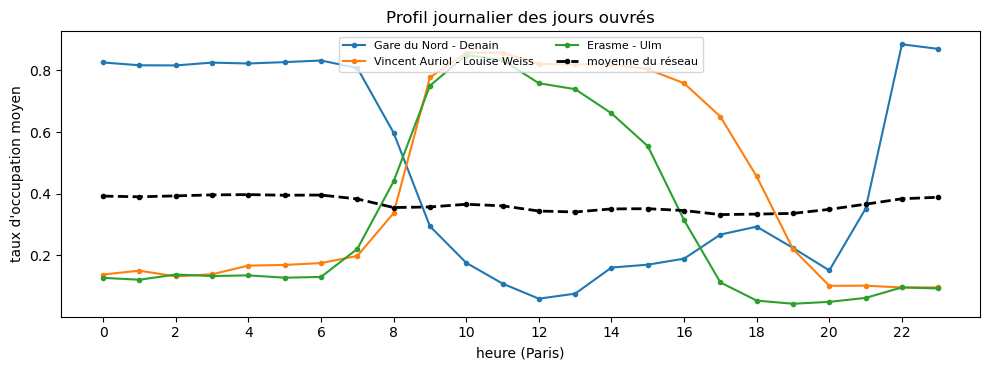

In [12]:
top3 = q3_pd.station_id.head(3).tolist()
courbes = spark.sql(f"""
    SELECT CAST(station_id AS STRING) AS station, heure, taux_heure FROM profils
    WHERE station_id IN ({", ".join(map(str, top3))})
    UNION ALL
    SELECT 'réseau', heure, avg(taux_heure) FROM profils GROUP BY heure
""").toPandas().pivot(index="heure", columns="station", values="taux_heure")
noms = dict(zip(q3_pd.station_id.astype(str), q3_pd.nom_station))

fig, ax = plt.subplots(figsize=(10, 3.8))
for colonne in courbes.columns:
    style = dict(color="black", linestyle="--", linewidth=2) if colonne == "réseau" else {}
    ax.plot(courbes.index, courbes[colonne], marker=".", label=noms.get(colonne, "moyenne du réseau"), **style)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("heure (Paris)")
ax.set_ylabel("taux d'occupation moyen")
ax.set_title("Profil journalier des jours ouvrés")
ax.legend(fontsize=8, loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

**Gare du Nord - Denain** a la plus forte saisonnalité intra-journalière (identifiant de substitution 100018 : la station n'existe plus dans le référentiel actuel). Son profil a une amplitude de **0,83** : presque vide en milieu de journée (minimum vers 12 h), presque pleine le soir (maximum vers 22 h). Avec un R² de 0,82, l'heure explique 82 % de la variance de ses relevés : le cycle est très régulier d'un jour ouvré à l'autre. Selon le R² seul, c'est sa voisine **Gare du Nord - Faubourg Saint-Denis** qui l'emporte (0,86, amplitude 0,75). Quel que soit le critère, la réponse est donc une station de la gare du Nord.

Le classement fait apparaître deux profils opposés :

- **gare et quartiers résidentiels** (les deux stations de la gare du Nord, Léon - Doudeauville) : vides en journée, pleines le soir. Le matin, on y prend un vélo (en sortant du train, ou en partant de chez soi) ; le soir, on l'y rapporte ;
- **lieux de travail et d'études** (Erasme - Ulm près de l'ENS, Vincent Auriol - Louise Weiss, Halle Freyssinet - Station F, Laffitte et Favart - Italiens près des Grands Boulevards) : pleines vers 9-11 h, vides le soir.

Le profil moyen du réseau varie beaucoup moins, puisque les stations qui se vident compensent celles qui se remplissent. Ces deux familles annoncent les **clusters** que le K-Means du carnet 05 devrait retrouver.

## 6. Delta Lake : écriture

On écrit en Delta trois familles de tables, dans `data/output/delta` :

- `disponibilite` (schéma cible, partitionnée par année et mois) : la table de référence que les carnets
  suivants liront. Pour simuler une **mise à jour incrémentale**, la version 0 s'arrête **la veille du
  dernier jour** (le 9 avril 2021, heure de Paris) ; ce dernier jour arrivera par `MERGE` ;
- `features_temporelles` : les fonctions de fenêtre de la section 3 ;
- les **résultats** des trois questions.

Les dossiers de ces tables sont d'abord supprimés : la version 0 est ainsi toujours l'écriture initiale,
même quand on rejoue le carnet.

In [13]:
from delta.tables import DeltaTable

TABLES_RESULTATS = ["q1_ruptures_matin", "q2_pluie", "q3_saisonnalite"]
for dossier in [DELTA_DISPONIBILITE, DELTA_FEATURES] + [DELTA / nom for nom in TABLES_RESULTATS]:
    shutil.rmtree(dossier, ignore_errors=True)

sc.setJobDescription("Delta : écriture de disponibilite")
local = F.from_utc_timestamp("horodatage", "Europe/Paris")
disponibilite_delta = (spark.table("disponibilite")
                       .withColumn("annee", F.year(local)).withColumn("mois", F.month(local)))
DERNIER_JOUR = spark.sql("SELECT max(date) FROM releves").first()[0]
t0 = time.perf_counter()
(disponibilite_delta.filter(F.to_date(local) < DERNIER_JOUR)
 .write.format("delta").partitionBy("annee", "mois").save(str(DELTA_DISPONIBILITE)))
t_delta = time.perf_counter() - t0

sc.setJobDescription("Delta : écriture de features_temporelles")
(spark.table("features_temporelles")
 .withColumn("annee", F.year("date")).withColumn("mois", F.month("date"))
 .write.format("delta").partitionBy("annee", "mois").save(str(DELTA_FEATURES)))

for nom, df in zip(TABLES_RESULTATS, [q1, q2_detail, q3]):
    df.write.format("delta").save(str(DELTA / nom))

print(f"disponibilite écrite en Delta en {t_delta:.1f} s, sans le {DERNIER_JOUR:%d/%m/%Y}")
for dossier in [DELTA_DISPONIBILITE, DELTA_FEATURES] + [DELTA / nom for nom in TABLES_RESULTATS]:
    taille = sum(f.stat().st_size for f in dossier.rglob("*.parquet")) / 1e6
    print(f"  {dossier.name:<22} {taille:7.1f} Mo  ({len(list((dossier / '_delta_log').glob('*.json')))} version(s))")

disponibilite écrite en Delta en 5.2 s, sans le 09/04/2021
  disponibilite             62.2 Mo  (1 version(s))


  features_temporelles     125.8 Mo  (1 version(s))
  q1_ruptures_matin          0.0 Mo  (1 version(s))
  q2_pluie                   0.0 Mo  (1 version(s))
  q3_saisonnalite            0.1 Mo  (1 version(s))


Une table Delta, c'est du **Parquet + un journal de transactions** (`_delta_log`) : chaque écriture ajoute
un fichier JSON qui liste les fichiers Parquet ajoutés et retirés. On le lit directement :

In [14]:
journal = DELTA_DISPONIBILITE / "_delta_log" / "00000000000000000000.json"
actions = [json.loads(ligne) for ligne in journal.read_text(encoding="utf-8").splitlines()]
for action in actions:
    cle = next(iter(action))
    if cle == "add":
        continue
    print(f"{cle:<10} {json.dumps(action[cle], ensure_ascii=False)[:150]}")
ajouts = [a["add"] for a in actions if "add" in a]
print(f"add        {len(ajouts)} fichiers Parquet, par ex. {ajouts[0]['path']}")

commitInfo {"timestamp": 1793284064070, "operation": "WRITE", "operationParameters": {"mode": "ErrorIfExists", "partitionBy": "[\"annee\",\"mois\"]"}, "isolation
metaData   {"id": "b198b563-e07e-4bf8-ae71-2229338be98f", "format": {"provider": "parquet", "options": {}}, "schemaString": "{\"type\":\"struct\",\"fields\":[{\"
protocol   {"minReaderVersion": 1, "minWriterVersion": 2}
add        6 fichiers Parquet, par ex. annee=2021/mois=1/part-00000-f35349b0-26eb-4314-a748-0de4f665188f.c000.snappy.parquet


## 7. `MERGE INTO` : mise à jour incrémentale et correction

Un seul `MERGE` applique, en **une transaction**, un lot qui mélange deux cas :

1. **livraison du dernier jour** : les relevés du 9 avril, absents de la version 0. Ils n'existent pas
   dans la table : ce sont des **insertions** ;
2. **correction** : « Parmentier - Abel rabaud » est l'ancienne graphie de « Parmentier - Abel Rabaud »
   (même position, même station 11035, carnet 01). Ses 612 relevés existent déjà : ce sont des
   **mises à jour**.

Le `MERGE` compare la source aux lignes cibles sur `(station_id, horodatage)` : mise à jour si la ligne
existe, insertion sinon. Si le lot est rejoué, il ne crée aucun doublon : c'est l'intérêt du `MERGE` sur
un simple ajout (`append`).

Une troisième correction avait été envisagée : réintégrer les 680 relevés d'« Arago - Paul Lafargue »,
écartés au carnet 02 pour leur longitude fausse. La cellule suivante montre pourquoi on y renonce.

In [15]:
SCHEMA_BRUT = ("horodatage TIMESTAMP, capacite INT, velos_mecaniques INT, velos_electriques INT, "
               "nom_station STRING, coordonnees STRING, en_service BOOLEAN")
(spark.read.schema(SCHEMA_BRUT).option("header", True).option("timestampFormat", "yyyy-MM-dd'T'HH:mmX")
 .csv(str(VELIB_RAW / "velib_*.csv.gz"))
 .filter(F.trim("nom_station").isin("Arago - Paul Lafargue", "Jean Jaurès - Paul Lafargue"))
 .createOrReplaceTempView("lafargue_brut"))
spark.sql("""
SELECT trim(nom_station) AS nom_station, coordonnees, count(*) AS releves,
       min(horodatage) AS premier, max(horodatage) AS dernier, max(capacite) AS capacite_max,
       max(velos_mecaniques + velos_electriques) AS velos_max, max(CAST(en_service AS INT)) AS en_service
FROM lafargue_brut GROUP BY 1, 2
""").show(truncate=False)

+---------------------------+-----------------+-------+-------------------+-------------------+------------+---------+----------+
|nom_station                |coordonnees      |releves|premier            |dernier            |capacite_max|velos_max|en_service|
+---------------------------+-----------------+-------+-------------------+-------------------+------------+---------+----------+
|Arago - Paul Lafargue      |48.88500,48.88500|680    |2021-04-01 14:04:00|2021-04-09 14:04:00|0           |0        |0         |
|Jean Jaurès - Paul Lafargue|48.88501,2.24857 |2      |2021-04-09 14:25:00|2021-04-09 14:37:00|0           |0        |0         |
+---------------------------+-----------------+-------+-------------------+-------------------+------------+---------+----------+



Les 680 relevés d'Arago (du 1er au 9 avril) ont tous une **capacité de 0, aucun vélo et la station hors
service** : c'est une station **en cours d'installation**. Elle est renommée « Jean Jaurès - Paul
Lafargue » le 9 avril, avec la bonne position, mais toujours fermée à la fin de l'historique. Corriger sa longitude n'apporterait que des lignes sans usage, que le nettoyage
écarterait de toute façon. On construit donc le lot avec les deux autres cas.

In [16]:
spark.sql(f"""
CREATE OR REPLACE TEMP VIEW lot_merge AS
SELECT d.station_id, d.nom_station, d.arrondissement, d.latitude, d.longitude, d.horodatage,
       d.velos_mecaniques, d.velos_electriques, d.bornettes_libres, d.capacite_totale,
       d.taux_occupation,
       year(from_utc_timestamp(d.horodatage, 'Europe/Paris'))  AS annee,
       month(from_utc_timestamp(d.horodatage, 'Europe/Paris')) AS mois,
       'livraison du dernier jour'                             AS motif
FROM disponibilite d
WHERE to_date(from_utc_timestamp(d.horodatage, 'Europe/Paris')) = DATE'{DERNIER_JOUR}'
UNION ALL
SELECT station_id, 'Parmentier - Abel Rabaud', arrondissement, latitude, longitude, horodatage,
       velos_mecaniques, velos_electriques, bornettes_libres, capacite_totale, taux_occupation,
       annee, mois, 'correction du nom'
FROM delta.`{DELTA_DISPONIBILITE}`
WHERE nom_station = 'Parmentier - Abel rabaud'
""")
spark.sql("""
SELECT motif, count(*) AS lignes, count(DISTINCT station_id) AS stations,
       min(horodatage) AS premier, max(horodatage) AS dernier
FROM lot_merge GROUP BY motif
""").show(truncate=False)
spark.table("lot_merge").drop("motif").createOrReplaceTempView("corrections")

+-------------------------+------+--------+-------------------+-------------------+
|motif                    |lignes|stations|premier            |dernier            |
+-------------------------+------+--------+-------------------+-------------------+
|correction du nom        |612   |1       |2020-11-26 12:59:00|2020-12-03 17:01:00|
|livraison du dernier jour|84692 |1366    |2021-04-08 22:05:00|2021-04-09 14:37:00|
+-------------------------+------+--------+-------------------+-------------------+



In [17]:
sc.setJobDescription("Delta : MERGE INTO")
t0 = time.perf_counter()
spark.sql(f"""
MERGE INTO delta.`{DELTA_DISPONIBILITE}` AS cible
USING corrections AS source
ON  cible.station_id = source.station_id
AND cible.horodatage = source.horodatage
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *
""")
t_merge = time.perf_counter() - t0

historique = spark.sql(f"DESCRIBE HISTORY delta.`{DELTA_DISPONIBILITE}`")
historique.select("version", "timestamp", "operation").show(truncate=False)
metriques = historique.filter("operation = 'MERGE'").first()["operationMetrics"]
print(f"MERGE en {t_merge:.1f} s")
for cle in ["numSourceRows", "numTargetRowsUpdated", "numTargetRowsInserted", "numTargetRowsDeleted",
            "numTargetFilesRemoved", "numTargetFilesAdded"]:
    print(f"  {cle:<24} {metriques[cle]}")

+-------+-----------------------+---------+
|version|timestamp              |operation|
+-------+-----------------------+---------+
|1      |2026-10-29 14:28:14.297|MERGE    |
|0      |2026-10-29 14:27:44.161|WRITE    |
+-------+-----------------------+---------+

MERGE en 6.9 s
  numSourceRows            85304
  numTargetRowsUpdated     612
  numTargetRowsInserted    84692
  numTargetRowsDeleted     0
  numTargetFilesRemoved    2
  numTargetFilesAdded      3


Le lot contient 85 304 lignes : les **84 692 relevés du 9 avril** (1 366 stations), tous **insérés**, et les **612 relevés renommés**, tous **mis à jour**. Delta n'a touché que le nécessaire : 2 fichiers retirés (les partitions de novembre et décembre 2020, qui contiennent les relevés renommés) et 3 ajoutés (ces deux fichiers réécrits, plus un fichier pour les relevés d'avril). Les autres partitions sont intactes.

Delta fonctionne en **copie à l'écriture** (*copy-on-write*) : un fichier qui contient une seule ligne modifiée est réécrit en entier, et l'ancien reste sur disque, ce qui permet le time travel ci-dessous (jusqu'à un `VACUUM`).

## 8. Time travel

Le journal garde les deux versions. `VERSION AS OF 0` relit la table **avant** le `MERGE`, sans copie :
Delta reprend simplement la liste de fichiers de la version 0.

In [18]:
sc.setJobDescription("Delta : time travel")
comparaison = spark.sql(f"""
SELECT 'version 0' AS version, count(*) AS lignes,
       sum(CAST(nom_station = 'Parmentier - Abel rabaud' AS INT)) AS graphie_rabaud,
       sum(CAST(to_date(from_utc_timestamp(horodatage, 'Europe/Paris')) = DATE'{DERNIER_JOUR}' AS INT))
                                                                  AS releves_dernier_jour
FROM delta.`{DELTA_DISPONIBILITE}` VERSION AS OF 0
UNION ALL
SELECT 'actuelle', count(*),
       sum(CAST(nom_station = 'Parmentier - Abel rabaud' AS INT)),
       sum(CAST(to_date(from_utc_timestamp(horodatage, 'Europe/Paris')) = DATE'{DERNIER_JOUR}' AS INT))
FROM delta.`{DELTA_DISPONIBILITE}`
""").toPandas()
display(comparaison)
v0, v1 = comparaison.lignes
assert v1 - v0 == int(metriques["numTargetRowsInserted"]), "écart de lignes différent des insertions"
assert comparaison.graphie_rabaud.tolist()[1] == 0
assert v1 == spark.table("disponibilite").count(), "la version actuelle doit contenir toute la période"

# La même relecture avec l'API DataFrame, et par date plutôt que par numéro de version
date_v0 = historique.filter("version = 0").first()["timestamp"]
n_par_date = (spark.read.format("delta").option("timestampAsOf", str(date_v0))
              .load(str(DELTA_DISPONIBILITE)).count())
print(f"timestampAsOf {date_v0} : {n_par_date:,} lignes".replace(",", " "))

,version,lignes,graphie_rabaud,releves_dernier_jour
0,version 0,10684570,612,0
1,actuelle,10769262,0,84692


timestampAsOf 2026-10-29 14:27:44.161000 : 10 684 570 lignes


## 9. Mesures et bilan

In [19]:
enregistrer_mesures("03_spark_sql_delta", {
    "cache_table_releves_s": round(t_cache, 2),
    "fenetres_cache_s": round(t_features, 2),
    "q1_s": round(t_q1, 2),
    "q3_s": round(t_q3, 2),
    "ecriture_delta_disponibilite_s": round(t_delta, 2),
    "merge_s": round(t_merge, 2),
    "merge_lignes_maj": int(metriques["numTargetRowsUpdated"]),
    "merge_lignes_inserees": int(metriques["numTargetRowsInserted"]),
    "pluie_ecart_taux_points": round(q2["ecart_taux_points"], 2),
    "pluie_ecart_mouvements_pct": round(q2["ecart_mouvements_pct"], 1),
})
print(json.dumps(json.loads(MESURES_JSON.read_text(encoding="utf-8"))["03_spark_sql_delta"], indent=2))

{
  "cache_table_releves_s": 5.55,
  "fenetres_cache_s": 6.5,
  "q1_s": 1.52,
  "q3_s": 3.07,
  "ecriture_delta_disponibilite_s": 5.16,
  "merge_s": 6.87,
  "merge_lignes_maj": 612,
  "merge_lignes_inserees": 84692,
  "pluie_ecart_taux_points": 1.33,
  "pluie_ecart_mouvements_pct": -23.1
}


## Bilan du Jour 2 matin

| Question | Réponse |
|---|---|
| Q1, ruptures entre 8 h et 10 h | Piat - Parc de Belleville (vide sur 37,9 % des relevés), puis cinq autres stations des hauteurs du 20e, trois de Fontenay-sous-Bois et une de la butte Montmartre ; 10,4 % de rupture le matin dans le 20e, moins de 0,5 % au centre |
| Q2, effet de la pluie | -23 % de mouvements de vélos (± 4,4) et +1,3 point de taux d'occupation (± 0,24), à heure et type de jour égaux |
| Q3, saisonnalité intra-journalière | Gare du Nord - Denain (amplitude 0,83, R² 0,82) : vide à midi, pleine à 22 h |

- **Fonctions de fenêtre** : `LAG` / `LEAD` avec l'écart de temps réel, et une moyenne mobile sur 3 heures définie en temps (`RANGE`), seule valable avec une collecte irrégulière. Elles forment la table Delta `features_temporelles`.
- **Delta Lake** : version 0 (10 684 570 lignes, sans le 9 avril), puis `MERGE` (84 692 insertions, 612 mises à jour) ; `VERSION AS OF 0` et `timestampAsOf` relisent l'état initial. La version actuelle de `delta/disponibilite` sert de référence aux carnets 04 et 05.
- **Performances** : avec `CACHE TABLE`, chaque question se calcule en 1 à 3 s sur 10,8 millions de relevés.

On libère les tables en cache puis la session.

In [20]:
spark.sql("UNCACHE TABLE features_temporelles")
spark.sql("UNCACHE TABLE releves")
spark.stop()
print("SparkSession arrêtée.")

SparkSession arrêtée.
